# Fiscycle Smart BSF — Model B1 Larval Growth Forecasting

**Status:** `RESEARCH_PROTOTYPE` · `NOT_FIELD_VALIDATED`

Eksperimen ini memprediksi **berat basah rata-rata larva (mg/individu) pada pengamatan berikutnya** dalam replikasi yang sama. Data adalah eksperimen publik, bukan sensor atau data lapangan Fiscycle. `moisture_percent` adalah level perlakuan kadar air substrat, bukan pembacaan sensor real-time.

Sumber: N. T. Eriksen, *Impact of substrate moisture content on growth and performance of black soldier fly larvae*, Mendeley Data v1 (2021), DOI `10.17632/k435zc736t.1`, CC BY 4.0.

In [1]:
from pathlib import Path
import hashlib, json, platform, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from openpyxl import load_workbook
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import joblib

SEED = 42
np.random.seed(SEED)
pd.set_option('display.max_columns', 100)

def find_project_root():
    required = {'Impact of substrate moisture content on BSF larvae Data.xlsx',
                'Fiscycle_BSF_SubstrateMoisture_LongForm_400rows.csv'}
    candidates = [Path.cwd(), Path.cwd() / '.agents' / 'skills' / 'fiscycle-bsf-ai']
    for candidate in candidates:
        data_candidate = candidate / 'data'
        if data_candidate.is_dir() and required.issubset({p.name for p in data_candidate.iterdir()}):
            return candidate.resolve()
    matches = list(Path.cwd().rglob('Impact of substrate moisture content on BSF larvae Data.xlsx'))
    for match in matches:
        if (match.parent / 'Fiscycle_BSF_SubstrateMoisture_LongForm_400rows.csv').exists():
            return (match.parent.parent if match.parent.name == 'data' else match.parent).resolve()
    raise FileNotFoundError('Folder fiscycle-bsf-ai dengan kedua input wajib tidak ditemukan.')

ROOT = find_project_root()
DATA_DIR = ROOT / 'data'
OUTPUT_DIR = ROOT / 'hasil'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
XLSX_PATH = DATA_DIR / 'Impact of substrate moisture content on BSF larvae Data.xlsx'
CSV_PATH = DATA_DIR / 'Fiscycle_BSF_SubstrateMoisture_LongForm_400rows.csv'
print('Project root:', ROOT)
print('Python:', sys.version.split()[0], '| pandas:', pd.__version__, '| sklearn:', sklearn.__version__)

# Reuse final estimator; calibration fits only missing development folds.
RUN_TRAINING = False
saved_summary = json.loads((OUTPUT_DIR / 'bsf_model_b1_evaluation_summary.json').read_text(encoding='utf-8'))
saved_metadata = json.loads((OUTPUT_DIR / 'bsf_model_b1_model_metadata.json').read_text(encoding='utf-8'))
saved_estimator_hash = hashlib.sha256((OUTPUT_DIR / 'bsf_model_b1_estimator.joblib').read_bytes()).hexdigest()
sys.path.insert(0, str(ROOT))

Project root: D:\project\Fyscycle\fiscycle-model-ai\.agents\skills\fiscycle-bsf-ai
Python: 3.13.3 | pandas: 3.1.0 | sklearn: 1.9.1


## 1. Audit workbook sumber dan CSV turunan

Workbook diperlakukan read-only. Validasi utama membandingkan `elapsed_days` dan `larval_wet_weight_mg` pada seluruh 400 titik terhadap blok sumber di sheet `Data on larvae`. Kolom turunan lain di CSV tidak dipakai sebagai prediktor karena banyak yang mengandung outcome atau informasi masa depan.

In [2]:
def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

raw_hash_before = sha256(XLSX_PATH)
csv_hash_before = sha256(CSV_PATH)
wb_values = load_workbook(XLSX_PATH, data_only=True, read_only=False)
wb_formulas = load_workbook(XLSX_PATH, data_only=False, read_only=False)
sheet_audit = {}
for ws in wb_values.worksheets:
    formula_count = sum(1 for row in wb_formulas[ws.title].iter_rows() for cell in row if cell.data_type == 'f')
    sheet_audit[ws.title] = {'rows': ws.max_row, 'columns': ws.max_column, 'formula_cells': formula_count}
display(pd.DataFrame(sheet_audit).T)

ws = wb_values['Data on larvae']
source_records = []
for time_row, weight_row in zip(range(2, 22), range(24, 44)):
    time_id, weight_id = ws.cell(time_row, 2).value, ws.cell(weight_row, 2).value
    if time_id != weight_id:
        raise ValueError(f'ID blok waktu dan wet weight tidak cocok: {time_id} vs {weight_id}')
    for measurement_index, col in enumerate(range(5, 25), start=1):
        source_records.append({
            'replicate_id': time_id,
            'measurement_index_1based': measurement_index,
            'source_elapsed_days': ws.cell(time_row, col).value,
            'source_weight_mg': ws.cell(weight_row, col).value,
        })
source_core = pd.DataFrame(source_records)
raw = pd.read_csv(CSV_PATH)
measurement_blocks = {
    'elapsed_days': ('Data on larvae', 2),
    'larval_wet_weight_mg': ('Data on larvae', 24),
    'larval_dry_mass_fraction': ('Data on larvae', 46),
    'larval_dry_weight_mg': ('Data on larvae', 68),
    'larval_organic_mass_mg': ('Data on larvae', 90),
    'ln_larval_organic_mass': ('Data on larvae', 112),
    'larval_carbon_mg': ('Data on larvae', 134),
    'total_larval_carbon_mg': ('Data on larvae', 156),
    'larval_CO2_ppm_per_s': ('Data on larvae', 180),
    'larval_CO2_mgC_per_day': ('Data on larvae', 202),
    'respiration_measurement_larvae_n': ('Data on larvae', 224),
    'larval_CO2_per_individual_mgC_day': ('Data on larvae', 246),
    'specific_CO2_per_day': ('Data on larvae', 268),
    'living_larvae_n': ('Data on larvae', 290),
    'survival_percent': ('Data on larvae', 312),
    'total_larval_CO2_mgC_per_day': ('Data on larvae', 334),
    'accum_larval_CO2_mgC': ('Data on larvae', 356),
    'ln_larval_dry_weight': ('Data on larvae', 378),
    'total_CO2_ppm_per_s': ('Data on larval cultures', 2),
    'headspace_height_cm': ('Data on larval cultures', 24),
    'headspace_volume_m3': ('Data on larval cultures', 46),
    'total_CO2_mgC_per_day': ('Data on larval cultures', 68),
    'accum_total_CO2_mgC': ('Data on larval cultures', 90),
    'microbial_CO2_mgC_per_day': ('Data on larval cultures', 112),
    'accum_microbial_CO2_mgC': ('Data on larval cultures', 134),
    'accum_microbial_CO2_percent_of_total': ('Data on larval cultures', 156),
    'water_added_ml': ('Data on larval cultures', 178),
    'accum_water_added_ml': ('Data on larval cultures', 200),
}
required_columns = {'replicate_id', 'moisture_percent', 'measurement_index_1based',
                    'elapsed_days', 'larval_wet_weight_mg'}
missing_columns = required_columns - set(raw.columns)
if missing_columns:
    raise ValueError(f'Kolom wajib hilang: {sorted(missing_columns)}')
comparison = raw.merge(source_core, on=['replicate_id', 'measurement_index_1based'], validate='one_to_one')
max_time_diff = float((comparison['elapsed_days'] - comparison['source_elapsed_days']).abs().max())
max_weight_diff = float((comparison['larval_wet_weight_mg'] - comparison['source_weight_mg']).abs().max())
column_validation = {}
for csv_column, (sheet_name, start_row) in measurement_blocks.items():
    block_ws = wb_values[sheet_name]
    block_records = []
    for row in range(start_row, start_row + 20):
        replicate_id = block_ws.cell(row, 2).value
        for measurement_index, col in enumerate(range(5, 25), start=1):
            block_records.append({'replicate_id': replicate_id, 'measurement_index_1based': measurement_index,
                                  'workbook_value': block_ws.cell(row, col).value})
    block = pd.DataFrame(block_records)
    checked = raw[['replicate_id', 'measurement_index_1based', csv_column]].merge(
        block, on=['replicate_id', 'measurement_index_1based'], validate='one_to_one')
    column_validation[csv_column] = float((pd.to_numeric(checked[csv_column]) -
                                                   pd.to_numeric(checked['workbook_value'])).abs().max())
max_all_measurement_diff = max(column_validation.values())

audit = {
    'rows': int(len(raw)), 'columns': int(raw.shape[1]),
    'replicates': int(raw['replicate_id'].nunique()),
    'moisture_levels': sorted(raw['moisture_percent'].unique().astype(int).tolist()),
    'observations_per_replicate': sorted(raw.groupby('replicate_id').size().unique().astype(int).tolist()),
    'missing_cells': int(raw.isna().sum().sum()),
    'duplicate_rows': int(raw.duplicated().sum()),
    'duplicate_keys': int(raw.duplicated(['replicate_id', 'measurement_index_1based']).sum()),
    'max_abs_elapsed_days_difference_vs_workbook': max_time_diff,
    'max_abs_wet_weight_mg_difference_vs_workbook': max_weight_diff,
    'validated_measurement_columns_against_workbook': int(len(column_validation)),
    'max_abs_difference_all_measurement_columns_vs_workbook': max_all_measurement_diff,
    'replicate_id_moisture_prefix_consistent': bool((raw['replicate_id'].str.split('-').str[0].astype(int) == raw['moisture_percent']).all()),
}
assert audit['rows'] == 400 and audit['replicates'] == 20
assert audit['moisture_levels'] == [45, 55, 65, 75]
assert audit['observations_per_replicate'] == [20]
assert audit['missing_cells'] == 0 and audit['duplicate_keys'] == 0
assert max_time_diff <= 1e-12 and max_weight_diff <= 1e-12
assert len(column_validation) == 28 and max_all_measurement_diff <= 1e-12
assert audit['replicate_id_moisture_prefix_consistent']
display(pd.Series(audit, name='verified_value').to_frame())
print('SHA256 workbook:', raw_hash_before)
print('SHA256 CSV:', csv_hash_before)

,rows,columns,formula_cells
Data on larvae,397,47,8735
Data on larval cultures,219,47,2443


,verified_value
rows,400
columns,31
replicates,20
moisture_levels,"[45, 55, 65, 75]"
observations_per_replicate,[20]
missing_cells,0
duplicate_rows,0
duplicate_keys,0
max_abs_elapsed_days_difference_vs_workbook,0.0
max_abs_wet_weight_mg_difference_vs_workbook,0.0


SHA256 workbook: 29853f53a3df8370d4097b3cbb931865455f267609c483c05dd0fae7a11f3f18
SHA256 CSV: 3ee922481a8f9fe9db9368d059c6e40b118becf5765b87051c991b2bed1166a0


,value
strictly_increasing_time_within_replicate,True
duplicate_replicate_timestamps,0
nonpositive_weights,0
exact_consecutive_flat_steps,0
decreasing_weight_steps_for_review,114
transition_count,380
interval_days_min,0.770833
interval_days_median,0.989583
interval_days_max,1.208333
weight_mg_min,1.82


,replicate_id,elapsed_days,larval_wet_weight_mg,weight_delta_mg
237,65-2,16.947917,233.24,-105.714
376,75-4,15.881945,301.60,-79.200
317,75-1,16.965278,248.50,-64.300
93,45-5,12.979167,177.60,-60.800
296,65-5,15.875000,276.30,-58.100
196,55-5,15.868056,242.00,-56.400
75,45-4,14.916667,195.72,-56.080
277,65-4,16.947917,228.30,-51.090
79,45-4,18.875000,158.32,-50.452
396,75-5,15.881945,312.10,-49.700


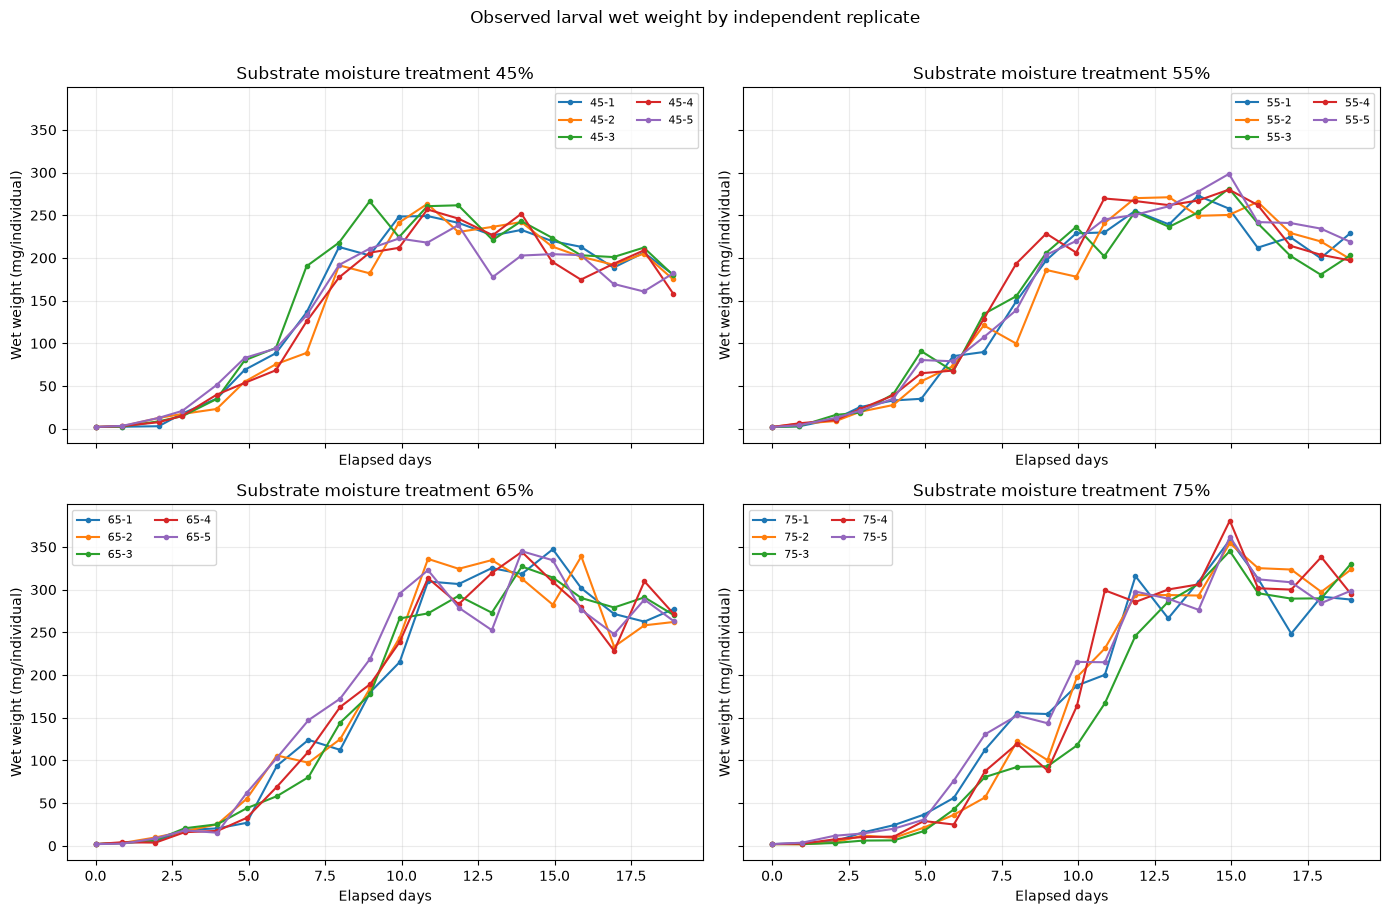

In [3]:
ordered = raw.sort_values(['replicate_id', 'elapsed_days']).copy()
ordered['time_delta_days'] = ordered.groupby('replicate_id')['elapsed_days'].diff()
ordered['weight_delta_mg'] = ordered.groupby('replicate_id')['larval_wet_weight_mg'].diff()
quality = {
    'strictly_increasing_time_within_replicate': bool(ordered['time_delta_days'].dropna().gt(0).all()),
    'duplicate_replicate_timestamps': int(raw.duplicated(['replicate_id', 'elapsed_days']).sum()),
    'nonpositive_weights': int((raw['larval_wet_weight_mg'] <= 0).sum()),
    'exact_consecutive_flat_steps': int(ordered['weight_delta_mg'].dropna().abs().lt(1e-12).sum()),
    'decreasing_weight_steps_for_review': int(ordered['weight_delta_mg'].lt(0).sum()),
    'transition_count': int(ordered['weight_delta_mg'].notna().sum()),
    'interval_days_min': float(ordered['time_delta_days'].min()),
    'interval_days_median': float(ordered['time_delta_days'].median()),
    'interval_days_max': float(ordered['time_delta_days'].max()),
    'weight_mg_min': float(raw['larval_wet_weight_mg'].min()),
    'weight_mg_max': float(raw['larval_wet_weight_mg'].max()),
}
display(pd.Series(quality, name='value').to_frame())
display(ordered.nsmallest(10, 'weight_delta_mg')[['replicate_id', 'elapsed_days', 'larval_wet_weight_mg', 'weight_delta_mg']])

fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True, sharey=True)
for ax, moisture in zip(axes.flat, [45, 55, 65, 75]):
    subset = ordered[ordered['moisture_percent'] == moisture]
    for replicate_id, group in subset.groupby('replicate_id'):
        ax.plot(group['elapsed_days'], group['larval_wet_weight_mg'], marker='o', ms=3, label=replicate_id)
    ax.set_title(f'Substrate moisture treatment {moisture}%')
    ax.set_xlabel('Elapsed days')
    ax.set_ylabel('Wet weight (mg/individual)')
    ax.grid(alpha=.25)
    ax.legend(fontsize=8, ncol=2)
fig.suptitle('Observed larval wet weight by independent replicate', y=1.01)
fig.tight_layout()
plt.show()

## 2. Framing, fitur, dan split bebas leakage

Pada waktu **t**, model memakai treatment moisture, elapsed day, berat saat ini, berat sebelumnya, laju perubahan historis, dan horizon terjadwal untuk memprediksi `weight_(t+1)` dalam replikasi yang sama. Horizon aktual antarpengamatan dipakai sebagai representasi jadwal yang diketahui; fungsi inferensi mewajibkan caller menyediakannya dan menolak horizon di luar rentang penelitian.

`replicate_id` hanya untuk grouping/split. Holdout final adalah suffix `-5` (satu replikasi per treatment). Empat fold development menahan suffix `-1` sampai `-4`, sehingga semua baris satu replikasi selalu berada pada partisi yang sama. Karena fitur trend memerlukan dua catatan historis, semua metode dibandingkan pada 360 pasangan yang sama.

In [4]:
pairs = ordered[['replicate_id', 'moisture_percent', 'measurement_index_1based',
                 'elapsed_days', 'larval_wet_weight_mg']].copy()
g = pairs.groupby('replicate_id', sort=False)
pairs['current_weight_mg'] = pairs['larval_wet_weight_mg']
pairs['previous_weight_mg'] = g['larval_wet_weight_mg'].shift(1)
pairs['previous_elapsed_days'] = g['elapsed_days'].shift(1)
pairs['target_weight_mg'] = g['larval_wet_weight_mg'].shift(-1)
pairs['target_elapsed_days'] = g['elapsed_days'].shift(-1)
pairs['history_interval_days'] = pairs['elapsed_days'] - pairs['previous_elapsed_days']
pairs['recent_growth_mg_per_day'] = (pairs['current_weight_mg'] - pairs['previous_weight_mg']) / pairs['history_interval_days']
pairs['forecast_horizon_days'] = pairs['target_elapsed_days'] - pairs['elapsed_days']
pairs = pairs.dropna(subset=['previous_weight_mg', 'target_weight_mg']).reset_index(drop=True)
assert len(pairs) == 360 and pairs.groupby('replicate_id').size().eq(18).all()
assert pairs['forecast_horizon_days'].gt(0).all() and pairs['history_interval_days'].gt(0).all()

FEATURES = ['moisture_percent', 'elapsed_days', 'current_weight_mg', 'previous_weight_mg',
            'recent_growth_mg_per_day', 'forecast_horizon_days']
TARGET = 'target_weight_mg'
TEST_IDS = ['45-5', '55-5', '65-5', '75-5']
test = pairs[pairs['replicate_id'].isin(TEST_IDS)].copy()
dev = pairs[~pairs['replicate_id'].isin(TEST_IDS)].copy()
assert set(dev['replicate_id']).isdisjoint(test['replicate_id'])
dev['cv_fold'] = dev['replicate_id'].str.split('-').str[-1].astype(int)
assert set(dev['cv_fold']) == {1, 2, 3, 4}
split_summary = {
    'development_replicates': sorted(dev['replicate_id'].unique().tolist()),
    'final_test_replicates': TEST_IDS,
    'development_samples': int(len(dev)), 'final_test_samples': int(len(test)),
    'fold_validation_replicates': {str(f): sorted(dev.loc[dev['cv_fold'] == f, 'replicate_id'].unique().tolist()) for f in range(1, 5)},
}
display(pd.Series(split_summary, name='value').to_frame())

,value
development_replicates,"[45-1, 45-2, 45-3, 45-4, 55-1, 55-2, 55-3, 55-..."
final_test_replicates,"[45-5, 55-5, 65-5, 75-5]"
development_samples,288
final_test_samples,72
fold_validation_replicates,"{'1': ['45-1', '55-1', '65-1', '75-1'], '2': [..."


## 3. Group-aware validation dan pemilihan model

Semua prediksi dibatasi minimal 0 mg. Tuning hanya melihat empat fold development. Holdout final belum dipakai saat memilih algoritma atau hiperparameter.

In [5]:
NUMERIC = ['elapsed_days', 'current_weight_mg', 'previous_weight_mg',
           'recent_growth_mg_per_day', 'forecast_horizon_days']
ridge_pre = ColumnTransformer([
    ('moisture', OneHotEncoder(handle_unknown='error', sparse_output=False), ['moisture_percent']),
    ('numeric', StandardScaler(), NUMERIC),
])
tree_pre = ColumnTransformer([
    ('moisture', OneHotEncoder(handle_unknown='error', sparse_output=False), ['moisture_percent']),
    ('numeric', 'passthrough', NUMERIC),
])

def ridge_model(alpha):
    return Pipeline([('preprocess', clone(ridge_pre)), ('model', Ridge(alpha=alpha))])

def hgb_model(params):
    return Pipeline([('preprocess', clone(tree_pre)),
                     ('model', HistGradientBoostingRegressor(random_state=SEED, max_iter=300,
                                learning_rate=params['learning_rate'], max_leaf_nodes=params['max_leaf_nodes'],
                                min_samples_leaf=params['min_samples_leaf'],
                                l2_regularization=params['l2_regularization']))])

def persistence(frame):
    return frame['current_weight_mg'].to_numpy()

def trend(frame):
    return np.maximum(0.0, frame['current_weight_mg'].to_numpy() +
                      frame['recent_growth_mg_per_day'].to_numpy() * frame['forecast_horizon_days'].to_numpy())

def metrics(y_true, y_pred):
    return {'mae_mg': float(mean_absolute_error(y_true, y_pred)),
            'rmse_mg': float(mean_squared_error(y_true, y_pred) ** 0.5),
            'bias_mg': float(np.mean(np.asarray(y_pred) - np.asarray(y_true))),
            'n': int(len(y_true))}

def cv_for_baseline(name, predictor):
    rows = []
    for fold in range(1, 5):
        valid = dev[dev['cv_fold'] == fold]
        row = metrics(valid[TARGET], predictor(valid)); row.update({'method': name, 'fold': fold})
        rows.append(row)
    return rows

def cv_for_model(name, model_factory, parameter_label):
    rows = []
    for fold in range(1, 5):
        train_fold, valid = dev[dev['cv_fold'] != fold], dev[dev['cv_fold'] == fold]
        model = model_factory()
        model.fit(train_fold[FEATURES], train_fold[TARGET])
        prediction = np.maximum(0.0, model.predict(valid[FEATURES]))
        row = metrics(valid[TARGET], prediction)
        row.update({'method': name, 'parameter_label': parameter_label, 'fold': fold})
        rows.append(row)
    return rows

if RUN_TRAINING:
    cv_rows = cv_for_baseline('persistence', persistence) + cv_for_baseline('trend', trend)
    for alpha in [0.1, 1.0, 10.0, 100.0]:
        cv_rows += cv_for_model('ridge', lambda a=alpha: ridge_model(a), f'alpha={alpha}')
    hgb_grid = [
        {'learning_rate': .03, 'max_leaf_nodes': 7, 'min_samples_leaf': 10, 'l2_regularization': 1.0},
        {'learning_rate': .05, 'max_leaf_nodes': 7, 'min_samples_leaf': 20, 'l2_regularization': 10.0},
        {'learning_rate': .03, 'max_leaf_nodes': 15, 'min_samples_leaf': 10, 'l2_regularization': 10.0},
        {'learning_rate': .05, 'max_leaf_nodes': 15, 'min_samples_leaf': 20, 'l2_regularization': 1.0},
    ]
    for i, params in enumerate(hgb_grid):
        cv_rows += cv_for_model('hist_gradient_boosting', lambda p=params: hgb_model(p), f'grid_{i}:{json.dumps(params, sort_keys=True)}')
    cv_results = pd.DataFrame(cv_rows)
    
    candidate_summary = (cv_results.groupby(['method', 'parameter_label'], dropna=False)
                         .agg(cv_mae_mean_mg=('mae_mg', 'mean'), cv_mae_std_mg=('mae_mg', 'std'),
                              cv_rmse_mean_mg=('rmse_mg', 'mean'), cv_bias_mean_mg=('bias_mg', 'mean'))
                         .reset_index())
    best_candidates = (candidate_summary.sort_values(['method', 'cv_mae_mean_mg'])
                       .groupby('method', as_index=False).first()
                       .sort_values('cv_mae_mean_mg').reset_index(drop=True))
    selected_method = best_candidates.iloc[0]['method']
    selected_parameter_label = best_candidates.iloc[0]['parameter_label']
    display(best_candidates)
    print('SELECTED FROM DEVELOPMENT CV:', selected_method, selected_parameter_label)
    
    best_ridge_alpha = float(best_candidates.loc[best_candidates['method'] == 'ridge', 'parameter_label'].iloc[0].split('=')[1])
    best_hgb_label = best_candidates.loc[best_candidates['method'] == 'hist_gradient_boosting', 'parameter_label'].iloc[0]
    best_hgb_params = json.loads(best_hgb_label.split(':', 1)[1])
    fitted_models = {'ridge': ridge_model(best_ridge_alpha),
                     'hist_gradient_boosting': hgb_model(best_hgb_params)}
    for model in fitted_models.values():
        model.fit(dev[FEATURES], dev[TARGET])
else:
    best_candidates = pd.DataFrame(saved_summary['development_cv_best_per_method'])
    selected_method = saved_summary['selected_from_development_cv']['method']
    selected_parameter_label = saved_summary['selected_from_development_cv']['parameter_label']
    fitted_models = {selected_method: joblib.load(OUTPUT_DIR / 'bsf_model_b1_estimator.joblib')}
    assert raw_hash_before == saved_summary['source']['workbook_sha256']
    assert csv_hash_before == saved_summary['source']['derived_csv_sha256']
    assert split_summary == saved_summary['split']
    display(best_candidates)
    print('Reusing selected estimator and archived CV results; no search or final fit.')

,method,parameter_label,cv_mae_mean_mg,cv_mae_std_mg,cv_rmse_mean_mg,cv_bias_mean_mg
0,hist_gradient_boosting,"grid_1:{""l2_regularization"": 10.0, ""learning_r...",17.995619,1.306219,23.944527,0.641366
1,ridge,alpha=1.0,25.638087,1.822336,32.159134,0.012209
2,persistence,NaN,27.602666,1.645549,36.550701,-13.147667
3,trend,NaN,35.394665,2.031342,48.290494,0.737078


Reusing selected estimator and archived CV results; no search or final fit.


## 4. Evaluasi holdout final (dibuka setelah pemilihan)

Setelah metode dan hiperparameter dipilih dari development CV, seluruh metode dilaporkan pada holdout yang sama untuk transparansi. Pemilihan tidak diubah berdasarkan hasil holdout.

Selected-model metrics verified now; comparator metrics are archived original evaluations.


,method,mae_mg,rmse_mg,bias_mg,n
0,hist_gradient_boosting,17.244599,22.821732,1.825013,72
1,ridge,23.972956,30.400118,-0.413540,72
2,persistence,26.910222,35.247838,-13.175389,72
3,trend,33.487910,45.789566,0.078164,72


Selected method holdout MAE improvement vs persistence: 35.92%


,moisture_percent,mae_mg,rmse_mg,bias_mg,n
0,45,15.566978,21.156755,9.960312,18.0
1,55,11.167385,15.220806,-5.639639,18.0
2,65,20.771313,24.008372,-1.817983,18.0
3,75,21.472720,28.768780,4.797363,18.0


,growth_phase,mae_mg,rmse_mg,bias_mg,n
0,early_<=6d,9.607237,13.259543,-4.469776,24.0
1,middle_6-13d,21.411402,28.062854,8.491015,28.0
2,late_>13d,20.575909,23.695600,0.046357,20.0


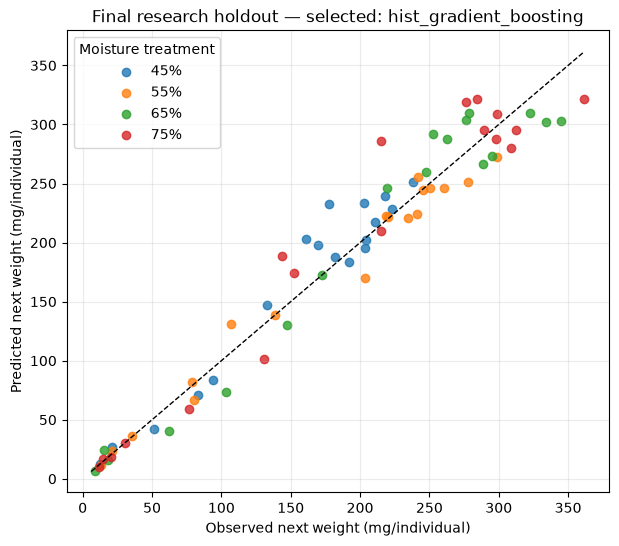

In [6]:
if RUN_TRAINING:
    test_predictions = {
        'persistence': persistence(test),
        'trend': trend(test),
        'ridge': np.maximum(0.0, fitted_models['ridge'].predict(test[FEATURES])),
        'hist_gradient_boosting': np.maximum(0.0, fitted_models['hist_gradient_boosting'].predict(test[FEATURES])),
    }
    test_metrics = pd.DataFrame([{'method': name, **metrics(test[TARGET], pred)}
                                 for name, pred in test_predictions.items()]).sort_values('mae_mg').reset_index(drop=True)
else:
    test_predictions = {selected_method: np.maximum(0.0, fitted_models[selected_method].predict(test[FEATURES]))}
    test_metrics = pd.DataFrame(saved_summary['final_holdout_metrics'])
    actual_metrics = metrics(test[TARGET], test_predictions[selected_method])
    previous_metrics = test_metrics.set_index('method').loc[selected_method]
    assert np.isclose(actual_metrics['mae_mg'], previous_metrics['mae_mg'], atol=1e-8)
    assert np.isclose(actual_metrics['rmse_mg'], previous_metrics['rmse_mg'], atol=1e-8)
    print('Selected-model metrics verified now; comparator metrics are archived original evaluations.')
display(test_metrics)
selected_test_prediction = test_predictions[selected_method]
persistence_test_mae = float(test_metrics.loc[test_metrics['method'] == 'persistence', 'mae_mg'].iloc[0])
selected_test_mae = float(test_metrics.loc[test_metrics['method'] == selected_method, 'mae_mg'].iloc[0])
test_improvement_vs_persistence_pct = 100.0 * (persistence_test_mae - selected_test_mae) / persistence_test_mae
print(f'Selected method holdout MAE improvement vs persistence: {test_improvement_vs_persistence_pct:.2f}%')

diagnostic = test[['replicate_id', 'moisture_percent', 'elapsed_days', 'target_elapsed_days',
                   'current_weight_mg', TARGET]].copy()
diagnostic['predicted_next_weight_mg'] = selected_test_prediction
diagnostic['error_mg'] = diagnostic['predicted_next_weight_mg'] - diagnostic[TARGET]
diagnostic['absolute_error_mg'] = diagnostic['error_mg'].abs()
diagnostic['growth_phase'] = pd.cut(diagnostic['elapsed_days'], bins=[-np.inf, 6, 13, np.inf],
                                    labels=['early_<=6d', 'middle_6-13d', 'late_>13d'])
per_moisture = (diagnostic.groupby('moisture_percent', observed=True)
                .apply(lambda x: pd.Series(metrics(x[TARGET], x['predicted_next_weight_mg'])), include_groups=False)
                .reset_index())
per_phase = (diagnostic.groupby('growth_phase', observed=True)
             .apply(lambda x: pd.Series(metrics(x[TARGET], x['predicted_next_weight_mg'])), include_groups=False)
             .reset_index())
display(per_moisture)
display(per_phase)

fig, ax = plt.subplots(figsize=(7, 6))
for moisture, group in diagnostic.groupby('moisture_percent'):
    ax.scatter(group[TARGET], group['predicted_next_weight_mg'], label=f'{moisture}%', alpha=.8)
lims = [min(diagnostic[TARGET].min(), diagnostic['predicted_next_weight_mg'].min()),
        max(diagnostic[TARGET].max(), diagnostic['predicted_next_weight_mg'].max())]
ax.plot(lims, lims, '--', color='black', lw=1)
ax.set(xlabel='Observed next weight (mg/individual)', ylabel='Predicted next weight (mg/individual)',
       title=f'Final research holdout — selected: {selected_method}')
ax.legend(title='Moisture treatment')
ax.grid(alpha=.25)
plt.show()

## 5. Visual perbandingan hasil

Dashboard membandingkan baseline dan kandidat ML pada sampel holdout yang sama. Historical replay menampilkan prediksi model terpilih terhadap observasi nyata dari replikasi yang tidak digunakan saat training/tuning.

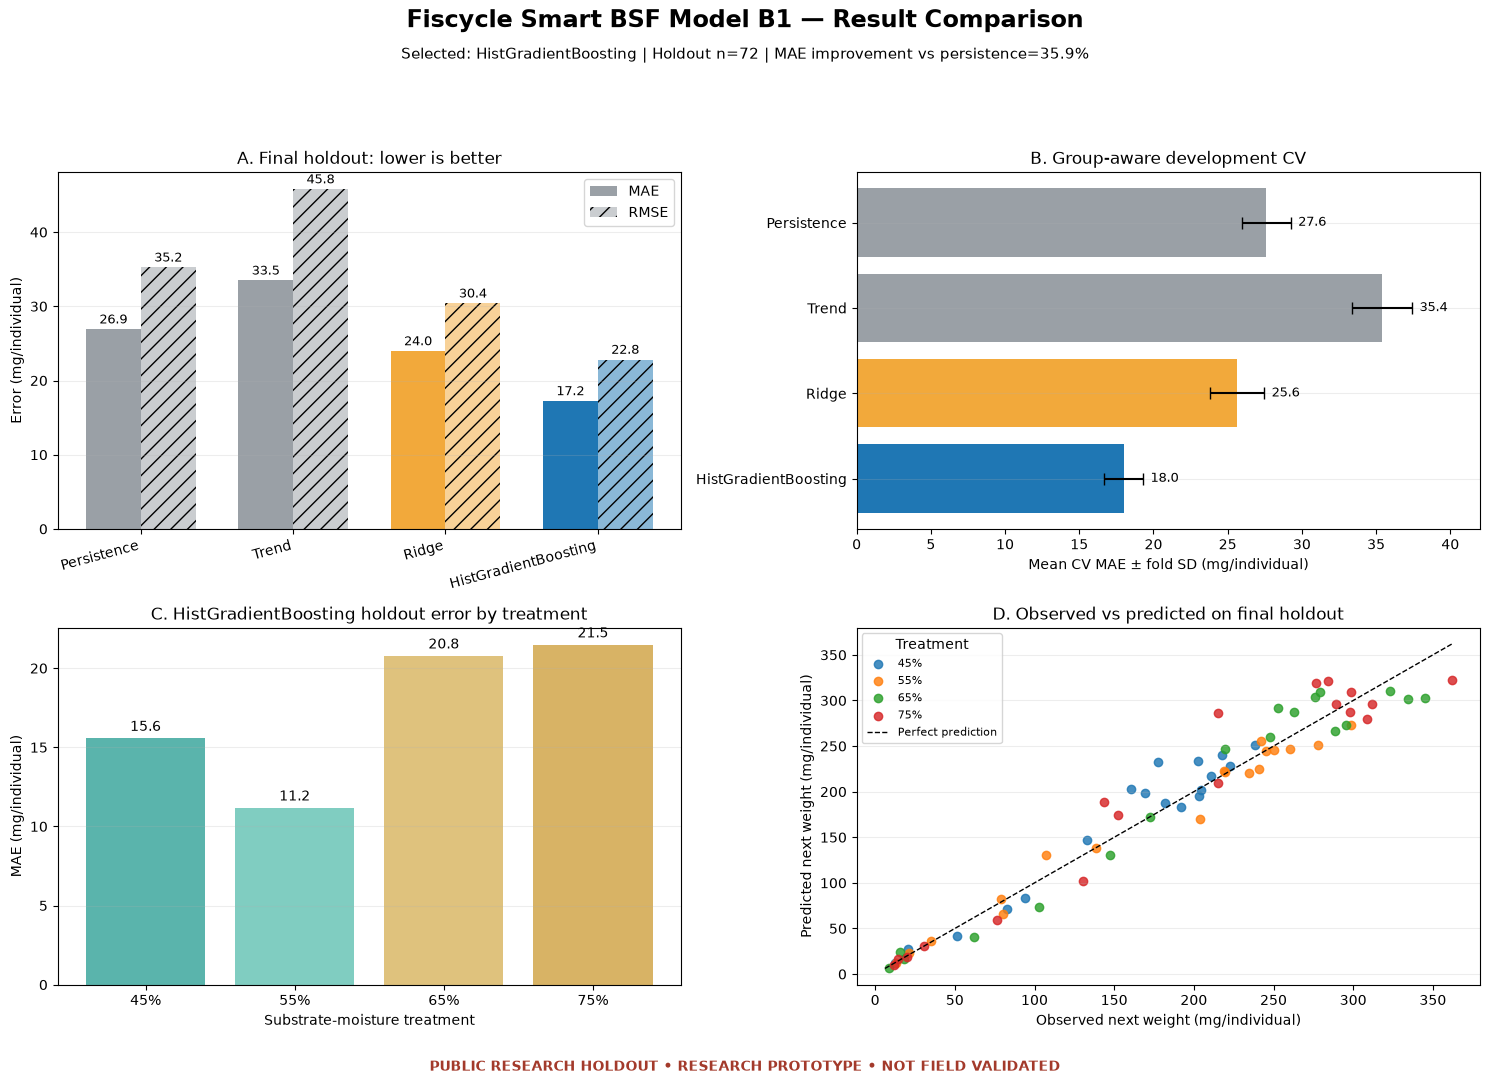

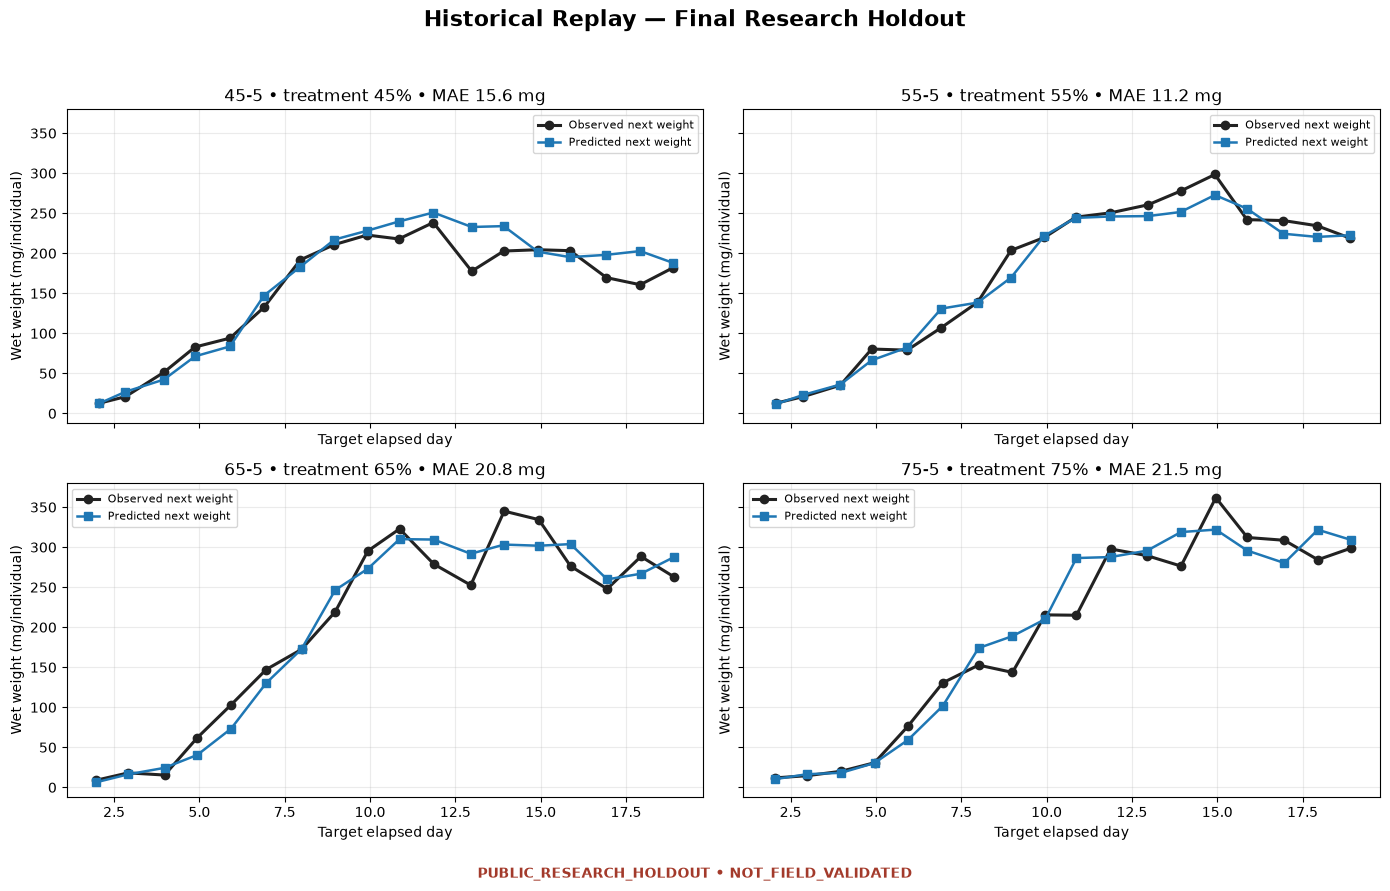

Visuals: bsf_model_b1_results_comparison.png bsf_model_b1_historical_replay_visual.png


In [7]:
method_order = ['persistence', 'trend', 'ridge', 'hist_gradient_boosting']
method_labels = {'persistence': 'Persistence', 'trend': 'Trend', 'ridge': 'Ridge',
                 'hist_gradient_boosting': 'HistGradientBoosting'}
comparison = test_metrics.set_index('method').loc[method_order].reset_index()
cv_comparison = best_candidates.set_index('method').loc[method_order].reset_index()
selected_color, baseline_color, other_color = '#1f77b4', '#9aa0a6', '#f2a93b'
bar_colors = [selected_color if method == selected_method else
              baseline_color if method in {'persistence', 'trend'} else other_color
              for method in method_order]

fig, axes = plt.subplots(2, 2, figsize=(15, 11))
x = np.arange(len(comparison))
width = 0.36
bars_mae = axes[0, 0].bar(x - width/2, comparison['mae_mg'], width, label='MAE', color=bar_colors)
bars_rmse = axes[0, 0].bar(x + width/2, comparison['rmse_mg'], width, label='RMSE',
                            color=bar_colors, alpha=.52, hatch='//')
axes[0, 0].set_xticks(x, [method_labels[m] for m in method_order], rotation=15, ha='right')
axes[0, 0].set_ylabel('Error (mg/individual)')
axes[0, 0].set_title('A. Final holdout: lower is better')
axes[0, 0].legend()
axes[0, 0].bar_label(bars_mae, fmt='%.1f', padding=2, fontsize=9)
axes[0, 0].bar_label(bars_rmse, fmt='%.1f', padding=2, fontsize=9)

axes[0, 1].barh(np.arange(len(cv_comparison)), cv_comparison['cv_mae_mean_mg'],
                  xerr=cv_comparison['cv_mae_std_mg'], color=bar_colors, capsize=4)
axes[0, 1].set_yticks(np.arange(len(cv_comparison)), [method_labels[m] for m in method_order])
axes[0, 1].invert_yaxis()
axes[0, 1].set_xlabel('Mean CV MAE ± fold SD (mg/individual)')
axes[0, 1].set_title('B. Group-aware development CV')
for y, value in enumerate(cv_comparison['cv_mae_mean_mg']):
    axes[0, 1].text(value + cv_comparison.iloc[y]['cv_mae_std_mg'] + .5, y, f'{value:.1f}', va='center', fontsize=9)

moisture_bars = axes[1, 0].bar(per_moisture['moisture_percent'].astype(str) + '%',
                                per_moisture['mae_mg'], color=['#5ab4ac', '#80cdc1', '#dfc27d', '#d8b365'])
axes[1, 0].set_xlabel('Substrate-moisture treatment')
axes[1, 0].set_ylabel('MAE (mg/individual)')
axes[1, 0].set_title(f'C. {method_labels[selected_method]} holdout error by treatment')
axes[1, 0].bar_label(moisture_bars, fmt='%.1f', padding=3)

for moisture, group in diagnostic.groupby('moisture_percent'):
    axes[1, 1].scatter(group[TARGET], group['predicted_next_weight_mg'], label=f'{moisture}%', alpha=.82)
axes[1, 1].plot(lims, lims, '--', color='black', lw=1, label='Perfect prediction')
axes[1, 1].set_xlabel('Observed next weight (mg/individual)')
axes[1, 1].set_ylabel('Predicted next weight (mg/individual)')
axes[1, 1].set_title('D. Observed vs predicted on final holdout')
axes[1, 1].legend(title='Treatment', fontsize=8)
for ax in axes.flat:
    ax.grid(axis='y', alpha=.22)
fig.suptitle('Fiscycle Smart BSF Model B1 — Result Comparison', fontsize=17, fontweight='bold')
fig.text(.5, .935,
         f'Selected: {method_labels[selected_method]} | Holdout n={len(test)} | MAE improvement vs persistence={test_improvement_vs_persistence_pct:.1f}%',
         ha='center', fontsize=11)
fig.text(.5, .015, 'PUBLIC RESEARCH HOLDOUT • RESEARCH PROTOTYPE • NOT FIELD VALIDATED',
         ha='center', color='#a33a2b', fontsize=10, fontweight='bold')
axes[0, 1].set_xlim(0, 42)
fig.tight_layout(rect=[0, .04, 1, .90])
comparison_visual_path = OUTPUT_DIR / 'bsf_model_b1_results_comparison.png'
fig.savefig(comparison_visual_path, dpi=180, bbox_inches='tight', facecolor='white')
plt.show()

fig, replay_axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True, sharey=True)
for ax, moisture in zip(replay_axes.flat, [45, 55, 65, 75]):
    group = diagnostic[diagnostic['moisture_percent'] == moisture].sort_values('target_elapsed_days')
    replicate_id = group['replicate_id'].iloc[0]
    ax.plot(group['target_elapsed_days'], group[TARGET], marker='o', lw=2.2,
            color='#222222', label='Observed next weight')
    ax.plot(group['target_elapsed_days'], group['predicted_next_weight_mg'], marker='s', lw=1.8,
            color=selected_color, label='Predicted next weight')
    mae = mean_absolute_error(group[TARGET], group['predicted_next_weight_mg'])
    ax.set_title(f'{replicate_id} • treatment {moisture}% • MAE {mae:.1f} mg')
    ax.set_xlabel('Target elapsed day')
    ax.set_ylabel('Wet weight (mg/individual)')
    ax.grid(alpha=.25)
    ax.legend(fontsize=8)
fig.suptitle('Historical Replay — Final Research Holdout', fontsize=16, fontweight='bold')
fig.text(.5, .015, 'PUBLIC_RESEARCH_HOLDOUT • NOT_FIELD_VALIDATED',
         ha='center', color='#a33a2b', fontsize=10, fontweight='bold')
fig.tight_layout(rect=[0, .04, 1, .95])
replay_visual_path = OUTPUT_DIR / 'bsf_model_b1_historical_replay_visual.png'
fig.savefig(replay_visual_path, dpi=180, bbox_inches='tight', facecolor='white')
plt.show()
print('Visuals:', comparison_visual_path.name, replay_visual_path.name)

## 6. Fungsi inferensi terbatas dan dua mode demo

Fungsi menolak treatment, unit/nilai, urutan waktu, panjang history, atau horizon yang tidak didukung. Hasil selalu membawa status riset. Historical replay memakai holdout asli; synthetic scenarios tidak dipakai untuk fit maupun metrik.

In [8]:
from bsf_b1_validation import run_validation
from bsf_b1_inference import B1Predictor, predict_next_weight as infer_b1

validation_summary = run_validation(ROOT)
b1_predictor = B1Predictor(OUTPUT_DIR)
feature_bounds = b1_predictor.bounds
SUPPORTED_MOISTURE = set(b1_predictor.moistures)

def predict_next_weight(history, moisture_percent, forecast_horizon_days):
    # Compatibility adapter; the integration contract uses six explicit feature fields.
    hist = pd.DataFrame(history)
    if len(hist) < 2 or not {'elapsed_days', 'wet_weight_mg'}.issubset(hist.columns):
        raise ValueError('Two complete history records required.')
    numeric = hist[['elapsed_days', 'wet_weight_mg']].to_numpy(dtype=float)
    if not np.isfinite(numeric).all() or (numeric < 0).any():
        raise ValueError('History must contain finite non-negative numbers.')
    if not hist.elapsed_days.diff().dropna().gt(0).all():
        raise ValueError('History must be strictly increasing in time.')
    prev, current = hist.iloc[-2], hist.iloc[-1]
    result = infer_b1({
        'moisture_percent': moisture_percent,
        'elapsed_days': float(current.elapsed_days),
        'current_weight_mg': float(current.wet_weight_mg),
        'previous_weight_mg': float(prev.wet_weight_mg),
        'recent_growth_mg_per_day': float((current.wet_weight_mg-prev.wet_weight_mg)/(current.elapsed_days-prev.elapsed_days)),
        'forecast_horizon_days': forecast_horizon_days,
    }, predictor=b1_predictor)
    if result['input_domain_status'] != 'IN_DOMAIN':
        raise ValueError('; '.join(result['warnings']))
    return {**result, 'predicted_next_weight_mg_per_individual': result['predicted_next_weight_mg']}

historical_replay = test[['replicate_id', 'moisture_percent', 'measurement_index_1based',
                          'elapsed_days', 'target_elapsed_days', 'forecast_horizon_days',
                          'current_weight_mg', TARGET]].copy()
historical_replay['predicted_next_weight_mg'] = selected_test_prediction
historical_replay['error_mg'] = historical_replay['predicted_next_weight_mg'] - historical_replay[TARGET]
historical_replay['absolute_error_mg'] = historical_replay['error_mg'].abs()
historical_replay['data_provenance'] = 'PUBLIC_RESEARCH_HOLDOUT'
historical_replay['validation_status'] = 'NOT_FIELD_VALIDATED'
historical_replay['model_method'] = selected_method
replay_path = OUTPUT_DIR / 'bsf_model_b1_historical_replay.csv'
historical_replay.to_csv(replay_path, index=False)

synthetic_rows = []
for moisture in sorted(SUPPORTED_MOISTURE):
    moisture_dev = dev[dev['moisture_percent'] == moisture]
    for quantile, label in [(0.35, 'mid_low'), (0.65, 'mid_high')]:
        elapsed = float(moisture_dev['elapsed_days'].quantile(quantile))
        current = float(moisture_dev['current_weight_mg'].quantile(quantile))
        growth_rate = float(moisture_dev['recent_growth_mg_per_day'].median())
        history_interval = float(moisture_dev['history_interval_days'].median())
        previous = current - growth_rate * history_interval
        horizon = float(moisture_dev['forecast_horizon_days'].median())
        history = [
            {'elapsed_days': elapsed - history_interval, 'wet_weight_mg': previous},
            {'elapsed_days': elapsed, 'wet_weight_mg': current},
        ]
        result = predict_next_weight(history, moisture, horizon)
        synthetic_rows.append({
            'scenario_id': f'SYN_{moisture}_{label}', 'moisture_percent': moisture,
            'previous_elapsed_days': history[0]['elapsed_days'], 'previous_weight_mg': previous,
            'elapsed_days': elapsed, 'current_weight_mg': current,
            'forecast_horizon_days': horizon,
            'predicted_next_weight_mg': result['predicted_next_weight_mg_per_individual'],
            'data_provenance': 'SYNTHETIC_SCENARIO', 'validation_status': 'NOT_FIELD_VALIDATED',
            'model_method': selected_method,
        })
synthetic_scenarios = pd.DataFrame(synthetic_rows)
synthetic_path = OUTPUT_DIR / 'bsf_model_b1_synthetic_scenarios.csv'
synthetic_scenarios.to_csv(synthetic_path, index=False)
display(historical_replay.head())
display(synthetic_scenarios)

{
  "fold_fits": 0,
  "decreases": {
    "count": 114,
    "transitions": 380,
    "late_target_day_gt13_count": 71,
    "late_share_of_decreases_pct": 62.280701754385966,
    "by_phase": [
      {
        "phase_at_target": "early_<=6d",
        "transitions": 120,
        "decreases": 8,
        "decrease_rate_pct": 6.666666666667,
        "mean_drop_mg": 4.388525,
        "largest_drop_mg": 23.416
      },
      {
        "phase_at_target": "late_>13d",
        "transitions": 120,
        "decreases": 71,
        "decrease_rate_pct": 59.166666666667,
        "mean_drop_mg": 26.33503943662,
        "largest_drop_mg": 105.714
      },
      {
        "phase_at_target": "middle_6-13d",
        "transitions": 140,
        "decreases": 35,
        "decrease_rate_pct": 25.0,
        "mean_drop_mg": 19.180857142857,
        "largest_drop_mg": 60.8
      }
    ],
    "by_moisture": [
      {
        "moisture_percent": 45,
        "transitions": 95,
        "decreases": 29,
        "decreas

,replicate_id,moisture_percent,measurement_index_1based,elapsed_days,target_elapsed_days,forecast_horizon_days,current_weight_mg,target_weight_mg,predicted_next_weight_mg,error_mg,absolute_error_mg,data_provenance,validation_status,model_method
72,45-5,45,2,0.875000,2.062500,1.187500,3.364,12.678,12.397612,-0.280388,0.280388,PUBLIC_RESEARCH_HOLDOUT,NOT_FIELD_VALIDATED,hist_gradient_boosting
73,45-5,45,3,2.062500,2.833333,0.770833,12.678,20.900,27.024518,6.124518,6.124518,PUBLIC_RESEARCH_HOLDOUT,NOT_FIELD_VALIDATED,hist_gradient_boosting
74,45-5,45,4,2.833333,3.958333,1.125000,20.900,51.278,42.238649,-9.039351,9.039351,PUBLIC_RESEARCH_HOLDOUT,NOT_FIELD_VALIDATED,hist_gradient_boosting
75,45-5,45,5,3.958333,4.875000,0.916667,51.278,82.962,71.329505,-11.632495,11.632495,PUBLIC_RESEARCH_HOLDOUT,NOT_FIELD_VALIDATED,hist_gradient_boosting
76,45-5,45,6,4.875000,5.895833,1.020833,82.962,94.000,83.673315,-10.326685,10.326685,PUBLIC_RESEARCH_HOLDOUT,NOT_FIELD_VALIDATED,hist_gradient_boosting


,scenario_id,moisture_percent,previous_elapsed_days,previous_weight_mg,elapsed_days,current_weight_mg,forecast_horizon_days,predicted_next_weight_mg,data_provenance,validation_status,model_method
0,SYN_45_mid_low,45,5.895833,113.040604,6.895833,120.9835,1.000000,164.392243,SYNTHETIC_SCENARIO,NOT_FIELD_VALIDATED,hist_gradient_boosting
1,SYN_45_mid_high,45,10.854167,204.893104,11.854167,212.8360,1.000000,232.658453,SYNTHETIC_SCENARIO,NOT_FIELD_VALIDATED,hist_gradient_boosting
2,SYN_55_mid_low,55,5.921875,91.197756,6.916667,98.3474,0.994792,141.863627,SYNTHETIC_SCENARIO,NOT_FIELD_VALIDATED,hist_gradient_boosting
3,SYN_55_mid_high,55,10.866319,221.418356,11.861111,228.5680,0.994792,245.048363,SYNTHETIC_SCENARIO,NOT_FIELD_VALIDATED,hist_gradient_boosting
4,SYN_65_mid_low,65,5.968750,92.261690,6.958333,104.5370,0.989583,155.284125,SYNTHETIC_SCENARIO,NOT_FIELD_VALIDATED,hist_gradient_boosting
5,SYN_65_mid_high,65,10.878472,261.639690,11.868056,273.9150,0.989583,304.579855,SYNTHETIC_SCENARIO,NOT_FIELD_VALIDATED,hist_gradient_boosting
6,SYN_75_mid_low,75,5.965278,65.920186,6.958333,77.0180,0.993056,120.229096,SYNTHETIC_SCENARIO,NOT_FIELD_VALIDATED,hist_gradient_boosting
7,SYN_75_mid_high,75,10.881944,274.538186,11.875000,285.6360,0.993056,303.831766,SYNTHETIC_SCENARIO,NOT_FIELD_VALIDATED,hist_gradient_boosting


## 7. Simpan ringkasan dan artefak yang dibenarkan

Estimator hanya diekspor bila ML dipilih pada development CV dan mengalahkan persistence pada CV. Semua hasil tetap prototipe riset.

In [9]:
if RUN_TRAINING:
    def records_jsonable(frame):
        return json.loads(frame.to_json(orient='records'))
    
    persistence_cv_mae = float(best_candidates.loc[best_candidates['method'] == 'persistence', 'cv_mae_mean_mg'].iloc[0])
    selected_cv_mae = float(best_candidates.iloc[0]['cv_mae_mean_mg'])
    export_model = selected_method in fitted_models and selected_cv_mae < persistence_cv_mae
    model_artifact = None
    metadata_artifact = None
    if export_model:
        model_artifact = OUTPUT_DIR / 'bsf_model_b1_estimator.joblib'
        joblib.dump(fitted_models[selected_method], model_artifact)
        metadata_artifact = OUTPUT_DIR / 'bsf_model_b1_model_metadata.json'
        model_metadata = {
            'status': 'RESEARCH_PROTOTYPE', 'validation': 'NOT_FIELD_VALIDATED',
            'method': selected_method, 'parameter_label': str(selected_parameter_label),
            'features': FEATURES, 'target': TARGET, 'target_unit': 'mg_per_individual',
            'supported_moisture_treatments_percent': sorted(SUPPORTED_MOISTURE),
            'feature_bounds_from_development_data': feature_bounds,
            'training_source': 'Mendeley Data v1, DOI 10.17632/k435zc736t.1, CC BY 4.0',
            'development_replicates': split_summary['development_replicates'],
            'excluded_final_test_replicates': TEST_IDS, 'seed': SEED,
        }
        metadata_artifact.write_text(json.dumps(model_metadata, indent=2), encoding='utf-8')
    
    summary = {
        'status': 'RESEARCH_PROTOTYPE', 'validation': 'NOT_FIELD_VALIDATED',
        'generated_by_notebook': 'bsf_model_b1_growth_forecasting.ipynb',
        'source': {
            'dataset': 'Impact of substrate moisture content on growth and performance of black soldier fly larvae',
            'version': 1, 'doi': '10.17632/k435zc736t.1', 'license': 'CC BY 4.0',
            'workbook_sha256': raw_hash_before, 'derived_csv_sha256': csv_hash_before,
        },
        'audit': {**audit, **quality, 'workbook_sheets': sheet_audit},
        'problem': {'prediction_time': 't', 'target': 'weight at next observation within same replicate',
                    'target_unit': 'mg_per_individual', 'features': FEATURES,
                    'pair_count_fair_comparison': int(len(pairs)),
                    'horizon_note': 'Observed schedule interval; caller must know requested horizon at inference.'},
        'split': split_summary, 'seed': SEED,
        'development_cv_best_per_method': records_jsonable(best_candidates),
        'selected_from_development_cv': {'method': selected_method, 'parameter_label': str(selected_parameter_label)},
        'final_holdout_metrics': records_jsonable(test_metrics),
        'selected_holdout_improvement_vs_persistence_percent': test_improvement_vs_persistence_pct,
        'selected_holdout_metrics_by_moisture': records_jsonable(per_moisture),
        'selected_holdout_metrics_by_growth_phase': records_jsonable(per_phase),
        'artifacts': {
            'historical_replay': replay_path.name, 'synthetic_scenarios': synthetic_path.name,
            'results_comparison_visual': comparison_visual_path.name,
            'historical_replay_visual': replay_visual_path.name,
            'model': model_artifact.name if model_artifact else None,
            'model_metadata': metadata_artifact.name if metadata_artifact else None,
        },
        'limitations': [
            'Public controlled experiment only; no Fiscycle field or sensor validation.',
            'Only four substrate-moisture treatments and the original study conditions are represented.',
            'Moisture is a treatment label, not dynamic sensor telemetry.',
            'Next observation intervals vary; results do not establish multiday or harvest-yield forecasting.',
            'Twenty biological replicates are limited; holdout contains only one replicate per treatment.',
            'Observed weight decreases were retained as measurements and warrant domain review.',
        ],
        'environment': {'python': platform.python_version(), 'pandas': pd.__version__,
                        'numpy': np.__version__, 'scikit_learn': sklearn.__version__,
                        'joblib': joblib.__version__},
    }
    summary_path = OUTPUT_DIR / 'bsf_model_b1_evaluation_summary.json'
    summary_path.write_text(json.dumps(summary, indent=2), encoding='utf-8')
    
    assert sha256(XLSX_PATH) == raw_hash_before and sha256(CSV_PATH) == csv_hash_before
    print('Raw inputs unchanged: PASS')
    print('Wrote:', summary_path.name, replay_path.name, synthetic_path.name)
    print('Model export:', model_artifact.name if model_artifact else 'NOT EXPORTED (selection criteria not met)')
    print(json.dumps(summary['selected_from_development_cv'], indent=2))
else:
    assert sha256(XLSX_PATH) == raw_hash_before and sha256(CSV_PATH) == csv_hash_before
    assert sha256(OUTPUT_DIR / 'bsf_model_b1_estimator.joblib') == saved_estimator_hash
    print('Original estimator, metadata and evaluation summary preserved; no re-export in reuse mode.')

Original estimator, metadata and evaluation summary preserved; no re-export in reuse mode.


## 8. Validation & productization

Default execution reuses the saved final estimator. Four development-fold fits reconstruct missing residuals once; later runs reuse a hash-checked cache. The original comparison table includes archived Ridge/baseline scores; selected-HGB predictions are verified against the saved evaluation.

Decrease audit phases use the end of each transition. Error-analysis phases use prediction time t. The empirical 0.90 absolute-residual quantile is calibrated on development OOF predictions only. Temporal dependence and prior hyperparameter selection on those folds preclude a coverage guarantee. The inspected holdout is used for post-hoc coverage reporting, never band tuning.

Integration uses `bsf_b1_inference.predict_next_weight` with the six fields in `hasil/v2/MODEL_B1_INTEGRATION_CONTRACT.md`. Unsupported input returns a null prediction and reason codes. No API or frontend is created.


# Model B1 — validation & productization


RESEARCH_PROTOTYPE / NOT_FIELD_VALIDATED. Sumber: Mendeley DOI 10.17632/k435zc736t.1, CC BY 4.0.


## Audit penurunan berat


114 dari 380 transisi menurun. 71 (62.3%) terjadi pada target elapsed day >13.

Fase audit ditentukan pada akhir transisi (target day); early <=6, middle >6 sampai 13, late >13. Rate memakai seluruh transisi dalam kelompok sebagai denominator.

| phase_at_target | transitions | decreases | decrease_rate_pct | mean_drop_mg | largest_drop_mg |
| --- | --- | --- | --- | --- | --- |
| early_<=6d | 120 | 8 | 6.667 | 4.389 | 23.416 |
| late_>13d | 120 | 71 | 59.167 | 26.335 | 105.714 |
| middle_6-13d | 140 | 35 | 25.000 | 19.181 | 60.800 |

| moisture_percent | transitions | decreases | decrease_rate_pct | mean_drop_mg | largest_drop_mg |
| --- | --- | --- | --- | --- | --- |
| 45 | 95 | 29 | 30.526 | 22.377 | 60.800 |
| 55 | 95 | 28 | 29.474 | 21.054 | 56.400 |
| 65 | 95 | 29 | 30.526 | 26.010 | 105.714 |
| 75 | 95 | 28 | 29.474 | 20.839 | 79.200 |

Semua observasi dipertahankan. Ini pola deskriptif dalam 20 replikasi, bukan bukti penyebab biologis. Pengukuran rata-rata, sampling larva, perubahan perkembangan, atau pencatatan memerlukan review ahli; penyebabnya belum dikonfirmasi.


## Error model tersimpan

72 pasangan dari 45-5, 55-5, 65-5, 75-5. Bias = prediksi - observasi; positif berarti overprediction. Fase error memakai waktu prediksi t, bukan target day.

| moisture_percent | n | mae_mg | rmse_mg | bias_mg | median_abs_error_mg | p90_abs_error_mg | max_abs_error_mg | overprediction_count | interval_coverage_pct |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 45 | 18 | 15.567 | 21.157 | 9.960 | 9.683 | 34.408 | 55.235 | 11 | 88.889 |
| 55 | 18 | 11.167 | 15.221 | -5.640 | 9.128 | 25.784 | 34.020 | 7 | 100.000 |
| 65 | 18 | 20.771 | 24.008 | -1.818 | 21.839 | 34.576 | 41.755 | 8 | 94.444 |
| 75 | 18 | 21.473 | 28.769 | 4.797 | 16.794 | 43.328 | 71.430 | 8 | 83.333 |

| growth_phase | n | mae_mg | rmse_mg | bias_mg | median_abs_error_mg | p90_abs_error_mg | max_abs_error_mg | overprediction_count | interval_coverage_pct |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| early_<=6d | 24 | 9.607 | 13.260 | -4.470 | 7.562 | 23.049 | 29.771 | 8 | 100.000 |
| late_>13d | 20 | 20.576 | 23.696 | 0.046 | 18.982 | 37.715 | 42.039 | 10 | 95.000 |
| middle_6-13d | 28 | 21.411 | 28.063 | 8.491 | 17.702 | 43.328 | 71.430 | 16 | 82.143 |


Kondisi yang diketahui pada t:

| recent_decrease_at_t | n | mae_mg | rmse_mg | bias_mg | median_abs_error_mg | p90_abs_error_mg | max_abs_error_mg | overprediction_count | interval_coverage_pct |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| False | 50 | 14.523 | 20.869 | 0.274 | 9.683 | 30.819 | 71.430 | 21 | 94.000 |
| True | 22 | 23.429 | 26.735 | 5.349 | 22.608 | 41.565 | 42.479 | 13 | 86.364 |

| current_weight_bin_mg | n | mae_mg | rmse_mg | bias_mg | median_abs_error_mg | p90_abs_error_mg | max_abs_error_mg | overprediction_count | interval_coverage_pct |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 0-100 | 23 | 9.290 | 13.078 | -3.929 | 6.125 | 23.271 | 29.771 | 8 | 100.000 |
| 100-200 | 13 | 18.850 | 24.186 | 8.799 | 16.904 | 40.435 | 45.309 | 8 | 84.615 |
| 200-300 | 30 | 20.330 | 26.284 | 2.971 | 14.017 | 41.827 | 71.430 | 15 | 86.667 |
| >300 | 6 | 28.831 | 29.542 | 3.045 | 29.494 | 35.041 | 37.477 | 3 | 100.000 |


Penurunan pada t+1 (analisis retrospektif; tidak tersedia saat inference):

| next_step_decrease_retrospective | n | mae_mg | rmse_mg | bias_mg | median_abs_error_mg | p90_abs_error_mg | max_abs_error_mg | overprediction_count | interval_coverage_pct |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| False | 48 | 12.737 | 17.102 | -5.566 | 10.209 | 29.162 | 41.755 | 16 | 97.917 |
| True | 24 | 26.260 | 31.265 | 16.606 | 26.208 | 44.460 | 71.430 | 18 | 79.167 |


Sepuluh error terbesar:

| replicate_id | elapsed_days | current_weight_mg | target_weight_mg | predicted_next_weight_mg | error_mg |
| --- | --- | --- | --- | --- | --- |
| 75-5 | 9.958 | 215.440 | 215.000 | 286.430 | 71.430 |
| 45-5 | 11.854 | 238.400 | 177.600 | 232.835 | 55.235 |
| 75-5 | 8.007 | 152.700 | 143.600 | 188.909 | 45.309 |
| 75-5 | 12.944 | 289.400 | 276.400 | 318.879 | 42.479 |
| 45-5 | 16.927 | 169.600 | 160.720 | 202.759 | 42.039 |
| 65-5 | 12.951 | 252.580 | 345.000 | 303.245 | -41.755 |
| 75-5 | 13.938 | 276.400 | 361.800 | 321.944 | -39.856 |
| 65-5 | 11.868 | 278.898 | 252.580 | 291.755 | 39.175 |
| 75-5 | 16.965 | 308.600 | 284.290 | 321.767 | 37.477 |
| 55-5 | 7.979 | 138.800 | 203.660 | 169.640 | -34.020 |

Pola pada holdout ini: error lebih besar pada fase tengah/akhir dan setelah penurunan historis; subset berat saat ini >300 mg juga memiliki MAE tinggi tetapi hanya enam sampel. Penurunan pada langkah berikutnya sering di-overpredict. Ini diagnosis retrospektif, bukan pemilihan ulang model atau aturan biologis.


## Interval error empiris

Radius = 40.7933 mg, quantile 0.90 (method=higher) dari 288 absolute residual OOF development, 16 replikasi, 4 fold. Tiap fold fit pada 12 replikasi. Interval = [max(0, prediksi-radius), prediksi+radius].

Cakupan terukur holdout: 66/72 (91.67%). Kalibrasi tidak memakai residual holdout atau data sintetis.

Cakupan OOF per replikasi berkisar 66.7% sampai 100.0%.

Angka 0.90 adalah quantile residual yang dipilih untuk deskripsi error, bukan peluang kebenaran suatu prediksi. Tidak ada jaminan coverage: residual dalam replikasi berkorelasi, CV juga dipakai untuk pemilihan hiperparameter, dan model fold berbeda ukuran training dengan model final.

Lebar interval tidak dituning terhadap holdout. Holdout sudah pernah ditinjau; analisis ini tidak menciptakan bukti validasi independen baru.


## Guardrails dan replay

| input_domain_status | n | mae_mg | rmse_mg | bias_mg | median_abs_error_mg | p90_abs_error_mg | max_abs_error_mg | overprediction_count | interval_coverage_pct |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| IN_DOMAIN | 72 | 17.245 | 22.822 | 1.825 | 13.867 | 39.006 | 71.430 | 34 | 91.667 |

| case | replicate_id | elapsed_days | actual_mg | predicted_mg | absolute_error_mg | covered |
| --- | --- | --- | --- | --- | --- | --- |
| low_error | 45-5 | 0.875 | 12.678 | 12.398 | 0.280 | True |
| typical_error | 55-5 | 14.931 | 242.000 | 255.798 | 13.798 | True |
| difficult_high_error | 75-5 | 9.958 | 215.000 | 286.430 | 71.430 | False |

Input harus enam angka finite dengan unit kontrak. Pelanggaran tipe, kelengkapan, konsistensi, dan domain menghasilkan prediksi null. Domain mengikuti metadata development. Lolos batas marginal tidak menjamin kombinasi fitur, substrat, atau lokasi sesuai studi.

Horizon memakai interval observasi aktual dalam eksperimen; penggunaan mengasumsikan jadwal horizon diketahui pada t. Akurasi tepat 24 jam belum divalidasi terpisah.


## Keputusan

GO untuk demo riset dan integrasi kontrak secara offline. NO-GO untuk keputusan operasional farm. Pengumpulan dan evaluasi replikasi lokal independen serta review biologis masih diperlukan.

Estimator final dan raw input tidak diubah. Empat fit tambahan hanya merekonstruksi residual validasi saat cache belum tersedia. Skenario sintetis tetap terpisah dan tidak dihitung dalam evaluasi.

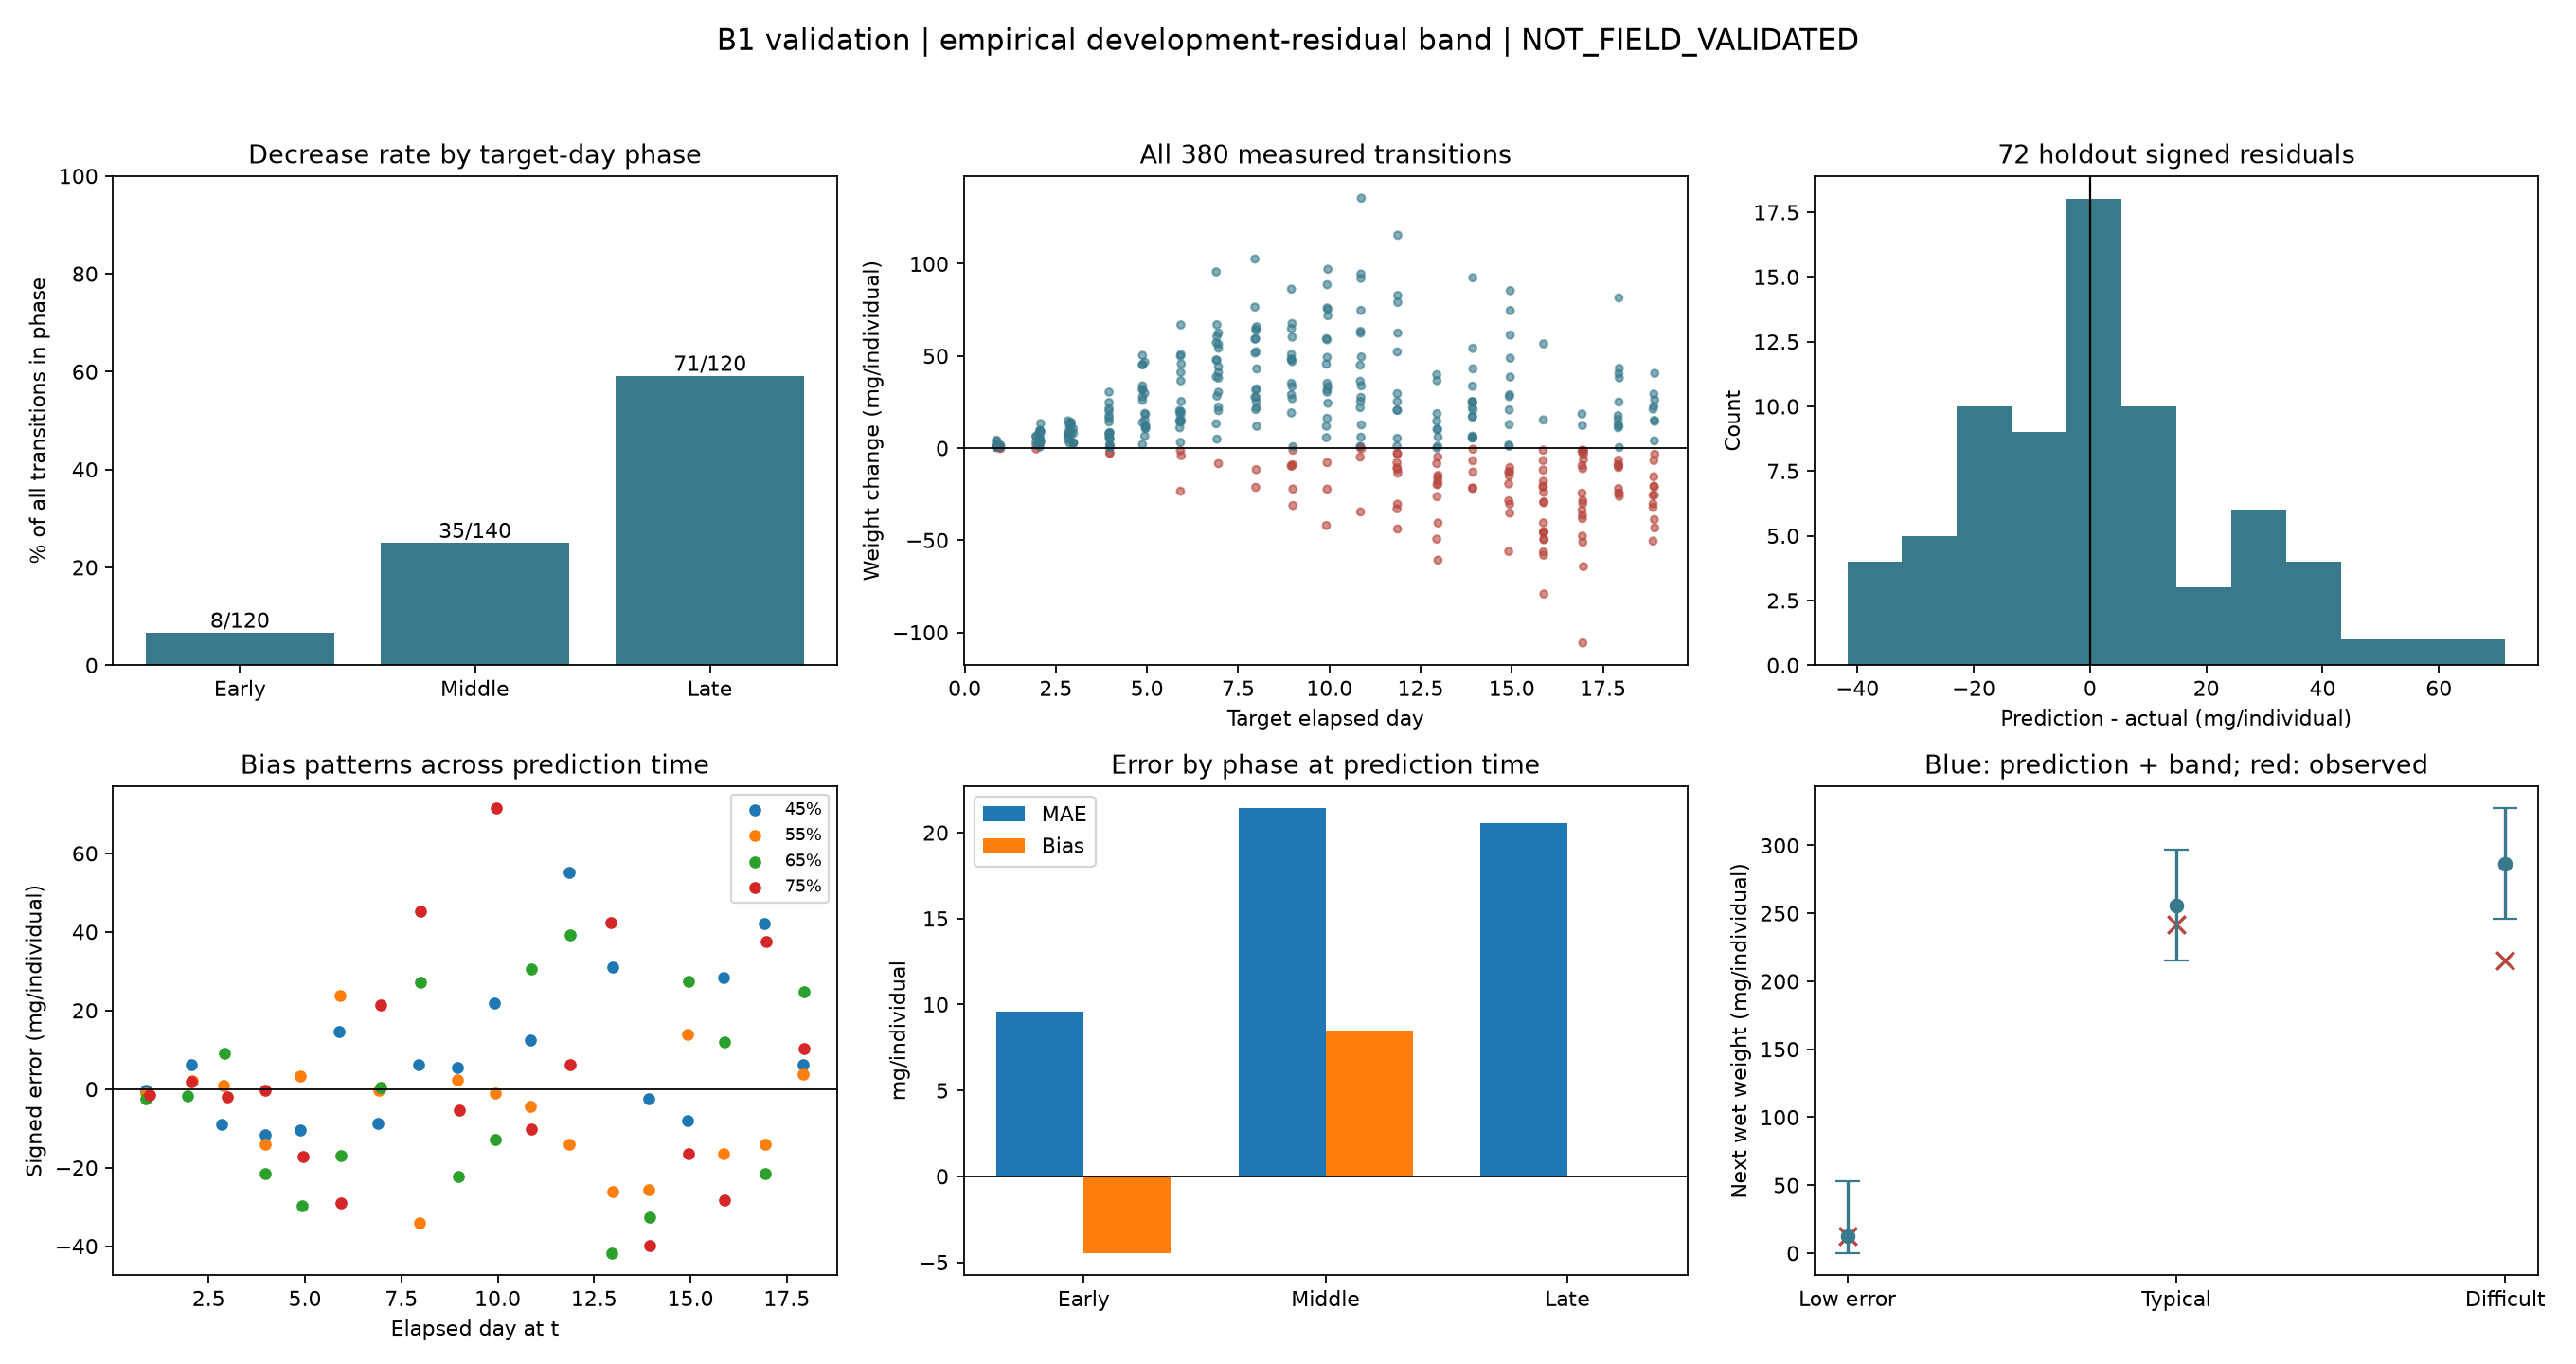

,case,replicate_id,elapsed_days,actual_mg,predicted_mg,absolute_error_mg,covered
0,low_error,45-5,0.875000,12.678,12.397612,0.280388,True
1,typical_error,55-5,14.930556,242.000,255.797851,13.797851,True
2,difficult_high_error,75-5,9.958333,215.000,286.429698,71.429698,False


test_all_holdout_predictions_match_saved_model (test_bsf_b1_inference.InferenceContractTests.test_all_holdout_predictions_match_saved_model) ... 

{
  "predicted_next_weight_mg": 255.7978506471848,
  "input_domain_status": "IN_DOMAIN",
  "warnings": [
    "EMPIRICAL_BAND_ONLY: correlated residuals and reused model-selection folds; no individual confidence guarantee.",
    "DOMAIN_CHECK_LIMITED: marginal numeric bounds do not validate substrate, site, or joint input combinations.",
    "CALLER_VERIFY: weights in mg/individual; growth from actual ordered history; horizon known at prediction time."
  ],
  "uncertainty": {
    "method": "development_group_oof_absolute_residual_quantile",
    "lower_mg": 215.00457867790442,
    "upper_mg": 296.59112261646516,
    "absolute_error_radius_mg": 40.79327196928037,
    "residual_quantile": 0.9,
    "calibration_rows": 288,
    "calibration_replicates": 16,
    "coverage_guaranteed": false
  },
  "model_status": "RESEARCH_PROTOTYPE",
  "validation_status": "NOT_FIELD_VALIDATED",
  "model_method": "hist_gradient_boosting",
  "training_source": "Mendeley Data v1, DOI 10.17632/k435zc736t.1, CC 

ok


test_calibration_excludes_test_and_synthetic (test_bsf_b1_inference.InferenceContractTests.test_calibration_excludes_test_and_synthetic) ... 

ok


... (12 outputs left out)

test_treatment_and_range_bounds (test_bsf_b1_inference.InferenceContractTests.test_treatment_and_range_bounds) ... 

ok


----------------------------------------------------------------------
Ran 9 tests in 0.860s

OK


Validation complete: final model and source data unchanged.


In [10]:
from IPython.display import Markdown, Image
import unittest
import test_bsf_b1_inference

display(Markdown((OUTPUT_DIR / 'v2' / 'bsf_model_b1_validation_report.md').read_text(encoding='utf-8')))
display(Image(filename=str(OUTPUT_DIR / 'v2' / 'bsf_model_b1_validation_visual.png')))
real_examples = json.loads((OUTPUT_DIR / 'v2' / 'detail' / 'bsf_model_b1_replay_examples.json').read_text(encoding='utf-8'))
display(pd.read_csv(OUTPUT_DIR / 'v2' / 'detail' / 'bsf_model_b1_replay_examples.csv'))
example_request = real_examples[1]['input']
example_response = infer_b1(example_request, predictor=b1_predictor)
print(json.dumps(example_response, indent=2, allow_nan=False))
tests = unittest.defaultTestLoader.loadTestsFromModule(test_bsf_b1_inference)
test_result = unittest.TextTestRunner(verbosity=2).run(tests)
assert test_result.wasSuccessful(), 'Inference contract tests failed'
assert sha256(OUTPUT_DIR / 'bsf_model_b1_estimator.joblib') == saved_estimator_hash
assert sha256(XLSX_PATH) == raw_hash_before and sha256(CSV_PATH) == csv_hash_before
print('Validation complete: final model and source data unchanged.')


## Kesimpulan penggunaan

Keputusan model mengikuti MAE rata-rata pada validasi group-aware, bukan holdout. Metrik holdout adalah ukuran pada empat replikasi penelitian yang benar-benar tidak terlihat saat fit/tuning. Hasil tidak mendukung klaim sensor live, generalisasi ke substrat/lokasi baru, prediksi yield kg, tanggal panen optimal, atau otomasi watering. Langkah ilmiah berikutnya adalah review anomali bersama ahli BSF dan pengumpulan replikasi lokal Fiscycle dengan protokol serta satuan yang terdokumentasi.